In [1]:
from graph_viz import draw_dot
import math
import random

In [2]:
class Value:
    def __init__ (self, data, children =(), op='', label=''):
        self.data=data
        self._prev=children
        self._op =op
        self.grad=0.0
        self.label=label
        self._backward=lambda: None

    def __repr__(self):
        return f'Value(data={self.data})'
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other),'+')
        def _backward():
            self.grad += out.grad
            other.grad +=  out.grad
        out._backward = _backward  
        return out
    
    def __radd__(self, other):
        return self*other
    
    def __neg__(self):
        return self * (-1)
    
    def __sub__(self, other):
        return self + (-other)
    
    def __rsub__(self, other):
        return self + (-other)
    
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other),'*')
        def _backward():
            self.grad += other.data*out.grad
            other.grad += self.data*out.grad
        out._backward = _backward    
        return out
    
    def __rmul__(self, other):
        return self*other

    
    def __pow__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data ** other.data, (self, other),'**')
        def _backward():
            self.grad += (math.pow(self.data, other.data-1) * other.data) * out.grad
            other.grad += (math.pow(self.data, other.data)*math.exp(self.data)) * out.grad
        out._backward=_backward    
        return out
    
    def __truediv__(self, other):
        return self * (other**-1)
    
    def __rtruediv__(self, other):
        return self * (other**-1)
    
    
    def exp(self):
        self = self if isinstance(self, Value) else Value(self)
        out = Value(math.exp(self.data),(self),op='exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward    
        return out
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo=[]
        visited=set()
        def build_topo(u):
            if u not in visited:
                visited.add(u)
                topo.append(u)                
                for child in u._prev:
                    build_topo(child)
        build_topo(self)
        self.grad=1.0
        for node in (topo):
            node._backward()
    

In [3]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

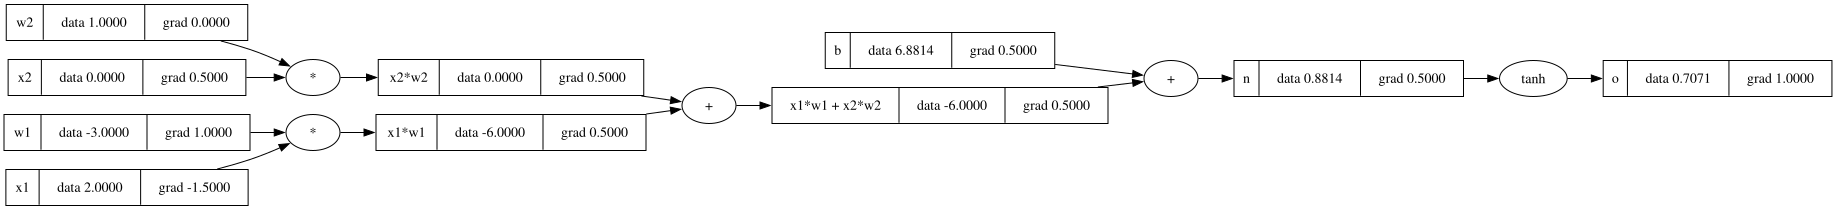

In [4]:
o.backward()
draw_dot(o)

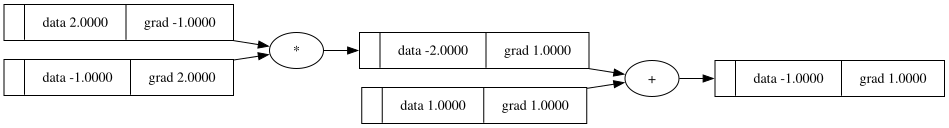

In [5]:
a=Value(2.0)
b=Value(1.0)
z=b-a
z.backward()
draw_dot(z)

In [6]:
class Neuron:
    def __init__ (self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    
    def __call__ (self, x):
        # w.T * x + b
        act = sum((wi*xi for wi, xi in zip(self.w,x)),start=self.b)
        out = act.tanh() 
        return out
    
    def parameters(self):
        return self.w + [self.b]
    

In [7]:
class Layer:
    def __init__ (self, nin, nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]
        
    def __call__ (self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs   
    
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

In [8]:
class MLP:
    def __init__ (self, nin, nouts: list):
        struc = [nin] + nouts
        self.layers = [Layer(struc[i],struc[i+1]) for i in range(len(nouts))]
        
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x  
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]  

In [72]:
model= MLP(3,[4,4,1])
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]


In [68]:
y_pred = [model(x) for x in xs]
y_pred

[Value(data=-0.1447981256656264),
 Value(data=-0.9746692208062481),
 Value(data=-0.9678502753588211),
 Value(data=0.33392325227073416)]

In [69]:
loss = sum([(ys[i]-y_pred[i])**2 for i in range(len(ys))])
loss

Value(data=0.4453334870346623)

In [70]:
loss.backward()

In [66]:
len(model.layers[2].parameters())

5

**A neuron network that has the structure (nin, [l1, l2, l3, ..., ln])**
- Number of parameters = (nin * l1 + l1) + (l1 * l2+l2) + ... + (ln-1 * ln+ln)

In [71]:
for p in model.parameters():
    p.data-=0.01*p.grad

In [81]:
def GD(X,model,epochs=10, lr=0.01):
    for epoch in range(epochs):
        y_pred = [model(x) for x in X]
        loss = sum([(ys[i]-y_pred[i])**2 for i in range(len(ys))])
        for p in model.parameters():
            p.grad = 0
        loss.backward()
        
        for p in model.parameters():
            p.data-=lr*p.grad
        
        print(f'Epoch {epoch+1}: Loss = {loss.data}')        

GD(xs, model)
        
        
        

Epoch 1: Loss = 0.07714912803974165
Epoch 2: Loss = 0.07560095095069419
Epoch 3: Loss = 0.0741064995514838
Epoch 4: Loss = 0.07266320320623645
Epoch 5: Loss = 0.07126864541654096
Epoch 6: Loss = 0.06992055284441409
Epoch 7: Loss = 0.0686167852320139
Epoch 8: Loss = 0.0673553261361169
Epoch 9: Loss = 0.06613427440360309
Epoch 10: Loss = 0.0649518363215356
